In [1]:
import os
import sys
from pathlib import Path

import torch
from dotenv import load_dotenv

project_root = Path().resolve().parent
sys.path.append(str(project_root))
sys.path.append(str(project_root / 'runs' / 'scripts'))
load_dotenv()

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

device: cuda


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from torchvision import transforms

from hierroute.constants import RESOLUTION
from hierroute.extra_functions import RandomBackgroundNoise, visualize_gradcam
from hierroute import HierRouteNet, Trainer, Visualize, visualize_swin_attention

# Shared builders / eval helpers (runs/scripts/)
from eval_loaders import build_test_loader, build_messy_loader, build_hier_dataset, train_val_test_split
from hiernet_eval import evaluate_checkpoint, per_class_outcomes, plot_outcome_stacked_bar

# Data

Two evaluation targets, both on HierNet's 17-leaf `HIERNET_CLASSES` taxonomy (`hiernet_adjacency_graph`) and both built through `runs/scripts/eval_loaders.py` so the constructions stay identical and seeded:

- **Test loader** -- the held-out split of the main `Hier-Zooplankton` dataset (`data_subdirectories=['IssacData']`, `Messy_background` images excluded), same seeded `0.7/0.1/0.2` split as `runs/train_swin_cnn_mnr.py`. The "same as training" target.
- **Messy loader** -- the full `Messy_background` set: real messy/dirty-background images the models never saw during training.

Both use a clean `Resize + ToTensor` pipeline (no training augmentation), so their metrics are directly comparable. Everything below (`# Evaluation`, `# Visualize`, `## Confidence`) runs on both.

## Test loader

Held-out test split of the main Hier-Zooplankton dataset -- deterministic on `SEED`, so it covers exactly the samples the released checkpoints were held out from. `train_val_test_split(test_hier_dataset)` recovers the matching train/val indices where needed.

In [3]:
test_hier_dataset, test_loader = build_test_loader()

[leaves_only] Kept 59546 samples | Removed 0 non-leaf samples

Total Dataset: Size = 59546 | Levels = 3
all_node_counts: {0: 59546, 1: 49546, 3: 26048, 6: 9999, 7: 9999, 8: 6050, 4: 17860, 9: 9950, 10: 3885, 11: 1277, 12: 1918, 13: 830, 5: 5638, 14: 1220, 15: 2483, 16: 799, 17: 1136, 2: 10000}

nodes_by_level: {0: [0], 1: [1, 2], 2: [3, 4, 5], 3: [6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]}


------------------------Level 0------------------------
Level: 0 | Class Name: root                 | Class Label:   0 | Type: Parent | Count:  59546 | Prop: 1.00

------------------------Level 1------------------------
Level: 1 | Class Name: Zoop-yes             | Class Label:   1 | Type: Parent | Count:  49546 | Prop: 0.83
Level: 1 | Class Name: Zoop-No              | Class Label:   2 | Type: Leaf   | Count:  10000 | Prop: 0.17

------------------------Level 2------------------------
Level: 2 | Class Name: Copepoda             | Class Label:   3 | Type: Parent | Count:  26048 | Prop: 0.44
Level

## Messy loader

Full `Messy_background` set (no per-class cap, no subdirectories). This is the held-out test set the original notebook reported on.

In [4]:
messy_hier_dataset, messy_loader = build_messy_loader()

[leaves_only] Kept 12314 samples | Removed 0 non-leaf samples

Total Dataset: Size = 12314 | Levels = 3
all_node_counts: {0: 12314, 1: 11922, 3: 6598, 6: 2210, 7: 1926, 8: 2462, 4: 2596, 9: 1369, 10: 556, 11: 221, 12: 216, 13: 234, 5: 2728, 14: 197, 15: 1400, 16: 615, 17: 516, 2: 392}

nodes_by_level: {0: [0], 1: [1, 2], 2: [3, 4, 5], 3: [6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]}


------------------------Level 0------------------------
Level: 0 | Class Name: root                 | Class Label:   0 | Type: Parent | Count:  12314 | Prop: 1.00

------------------------Level 1------------------------
Level: 1 | Class Name: Zoop-yes             | Class Label:   1 | Type: Parent | Count:  11922 | Prop: 0.97
Level: 1 | Class Name: Zoop-No              | Class Label:   2 | Type: Leaf   | Count:    392 | Prop: 0.03

------------------------Level 2------------------------
Level: 2 | Class Name: Copepoda             | Class Label:   3 | Type: Parent | Count:   6598 | Prop: 0.54
Level: 2 | Cla

# Visualize

Nauplius_Copepod: 4235 in train split | 2462 in Messy_background


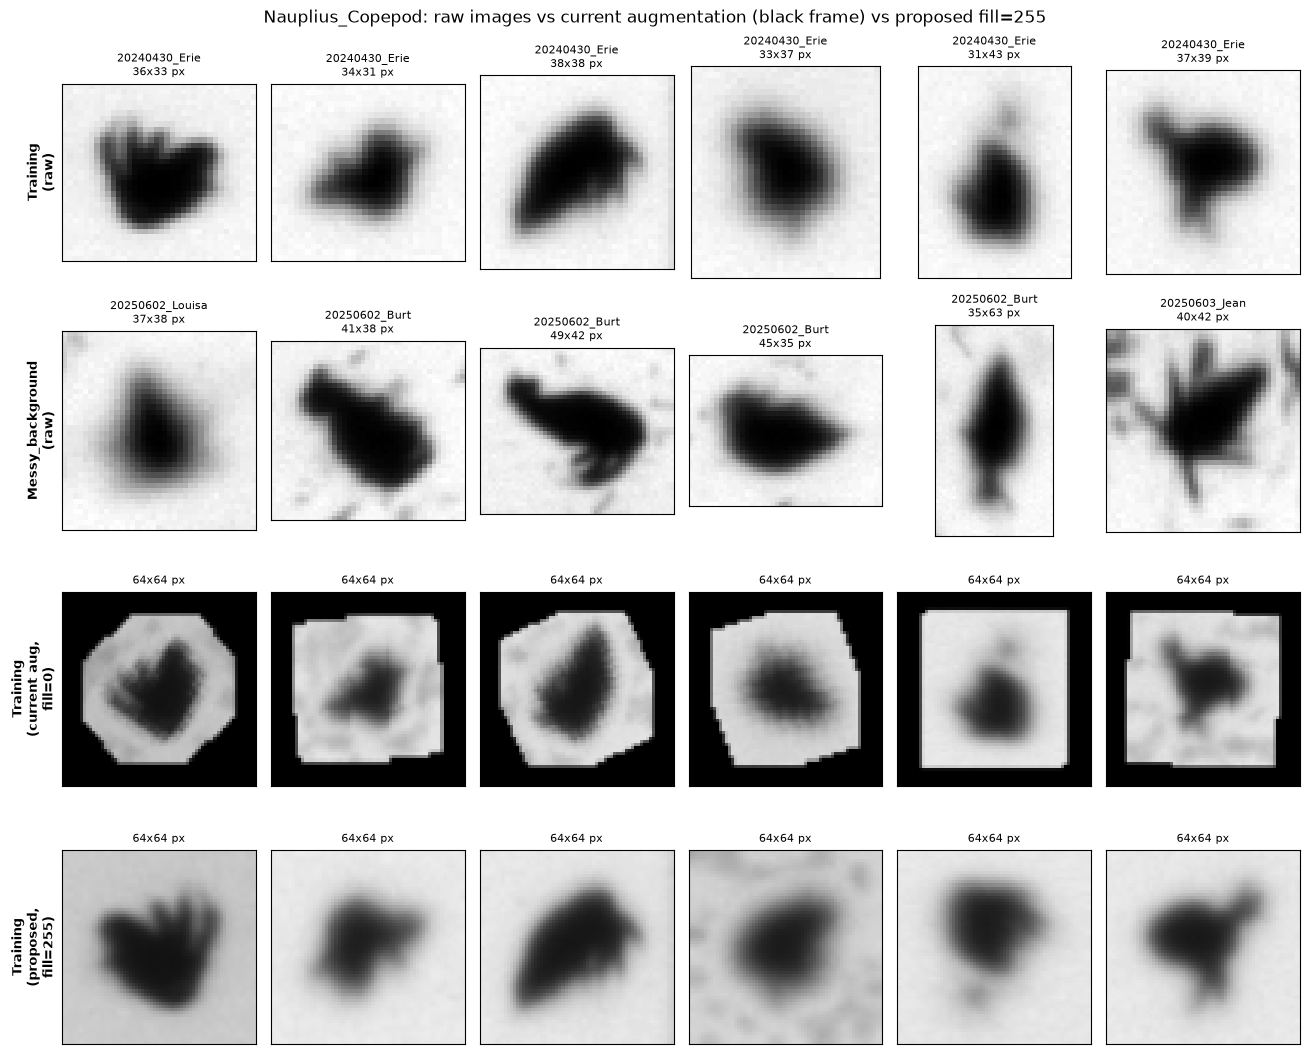

In [5]:
# Nauplius_Copepod: raw training vs raw Messy_background, plus the same training images
# through (3) the current training augmentation and (4) the proposed fill=255 fix.
#
# Rows 1-2 are raw at native resolution -- images are opened directly with PIL here
# (bypassing any dataset transform), so raw is the cleanest like-for-like appearance
# comparison regardless of what pipeline test_hier_dataset carries.
#
# Row 3 is what the model actually sees during training today. The black frame is NOT in
# the source data: RandomRotation(fill=0) blacks out corners that rotate in from outside
# the original crop, and Pad(fill=0) adds a black border on top. Both eval loaders (Resize
# + ToTensor only) produce neither, so the model trains with a frame it never sees at eval.
#
# Row 4 is the proposed fix. Note BOTH transforms need changing -- setting Pad(fill=255)
# alone still leaves black rotation corners, since RandomRotation also defaults to fill=0.
import random
from PIL import Image

CLASS_NAME = 'Nauplius_Copepod'
N_SHOW = 6
rng = random.Random(0)

train_split, _, _ = train_val_test_split(test_hier_dataset)
class_id = test_hier_dataset.label_to_ids[CLASS_NAME]
train_idx = [i for i in train_split if test_hier_dataset.labels[i] == class_id]
messy_idx = [i for i, lbl in enumerate(messy_hier_dataset.labels) if lbl == class_id]
print(f'{CLASS_NAME}: {len(train_idx)} in train split | {len(messy_idx)} in Messy_background')

train_pick = rng.sample(train_idx, min(N_SHOW, len(train_idx)))
messy_pick = rng.sample(messy_idx, min(N_SHOW, len(messy_idx)))

_SHARED = [RandomBackgroundNoise(p=0.5), transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip()]

# Mirrors train_variant(add_noise=True) below
current_transforms = transforms.Compose([
    *_SHARED,
    transforms.RandomRotation(180),
    transforms.Pad(padding=5, fill=0),
    transforms.Resize((RESOLUTION, RESOLUTION)),
    transforms.ToTensor(),
])

# Proposed: fill with the light background level instead of black
proposed_transforms = transforms.Compose([
    *_SHARED,
    # transforms.RandomRotation(180, fill=208),
    # transforms.Pad(padding=5, fill=208),
    transforms.Resize((RESOLUTION, RESOLUTION)),
    transforms.ToTensor(),
])

rows = [
    ('Training\n(raw)',                  test_hier_dataset,  train_pick, None),
    ('Messy_background\n(raw)',          messy_hier_dataset, messy_pick, None),
    ('Training\n(current aug,\nfill=0)',  test_hier_dataset,  train_pick, current_transforms),
    ('Training\n(proposed,\nfill=255)',   test_hier_dataset,  train_pick, proposed_transforms),
]

# The transforms draw from the global torch/random streams; snapshot and restore them so
# this cell leaves seeding untouched for the training cells below.
_torch_state, _py_state = torch.get_rng_state(), random.getstate()

fig, axes = plt.subplots(len(rows), N_SHOW, figsize=(2.2 * N_SHOW, 2.7 * len(rows)))
for r, (row_label, ds, idxs, tf) in enumerate(rows):
    for c in range(N_SHOW):
        ax = axes[r][c]
        ax.set_xticks([]); ax.set_yticks([])
        if c >= len(idxs):
            ax.axis('off')
            continue
        path = ds.image_paths[idxs[c]]
        img = Image.open(path).convert('L')
        if tf is None:
            ax.imshow(img, cmap='gray')
            # filename prefix is the sampling event (date_lake) -- worth showing, since the
            # train set is Lake Erie 2024 and Messy_background is 2025 inland lakes
            stem = os.path.basename(path)
            ax.set_title('_'.join(stem.split('_')[:2]) + f'\n{img.size[0]}x{img.size[1]} px', fontsize=8)
        else:
            ax.imshow(tf(img)[0].numpy(), cmap='gray', vmin=0, vmax=1)
            ax.set_title(f'{RESOLUTION}x{RESOLUTION} px', fontsize=8)
    axes[r][0].set_ylabel(row_label, fontsize=9, fontweight='bold')

torch.set_rng_state(_torch_state)
random.setstate(_py_state)

fig.suptitle(f'{CLASS_NAME}: raw images vs current augmentation (black frame) vs proposed fill=255',
             fontsize=12)
plt.tight_layout()
plt.show()


# Training

Two `HierRouteNet(backbone='swin_t', expert_type='cnn')` models, differing only in whether `RandomBackgroundNoise` (synthetic dirt) is applied during training -- mirrors `runs/train_swin_cnn_mnr.py`. Checkpoints already exist under `training_result/mnr/swin_t_cnn_baseline` and `swin_t_cnn_noise`, so re-running `train_variant(...)` below is optional (and slow, ~40 epochs each). `Trainer` won't overwrite an existing `model_dir` -- it appends `_1`, `_2`, ... instead -- so it's safe to re-run.

In [6]:
def train_variant(add_noise: bool, epochs=40, lr=3e-4, patience=10, delta=0.001):
    variant = 'noise' if add_noise else 'baseline'

    train_transforms_list = []
    if add_noise:
        # Applied first, on the raw native-resolution image, since add_synthetic_dirt's
        # speck/fiber sizes were calibrated against real messy-background images at their
        # original resolution -- applying it after Resize would distort those proportions.
        train_transforms_list.append(RandomBackgroundNoise(p=0.5))
    train_transforms_list += [
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(),
        transforms.RandomRotation(180),
        transforms.Pad(padding=5, fill=0),
        transforms.Resize((RESOLUTION, RESOLUTION)),
        transforms.ToTensor(),
    ]

    # Private dataset instance -- train_variant mutates its transform pipeline, so keep it
    # separate from test_hier_dataset (which feeds test_loader). Same seeded split as the
    # eval loaders, so train/val line up with the released checkpoints.
    hier_dataset = build_hier_dataset(print_details=False)
    hier_dataset.append_image_transforms(transforms.Compose(train_transforms_list), replace=True)
    train_split, val_split, test_split = train_val_test_split(hier_dataset)

    train_loader, val_loader, _ = hier_dataset.create_dataloaders(
        batch_size=64,
        train_indices=train_split,
        val_indices=val_split,
        test_indices=test_split,
        balanced=True,
    )

    model = HierRouteNet(
        hierarchy=hier_dataset.hierarchy,
        label_to_id=hier_dataset.label_to_ids,
        backbone='swin_t',
        expert_type='cnn',
        freeze_backbone=False,
    )

    model_dir = str(project_root / f'training_result/mnr/swin_t_cnn_{variant}')
    trainer = Trainer(learning_rate=lr, max_epochs=epochs, device=device, print_every=1, model_dir=model_dir)
    trainer.fit(model, train_loader, val_loader, scheduler=True, patience=patience, delta=delta)
    return trainer.model_dir

In [7]:
# Uncomment to (re)train from scratch:
# baseline_dir = train_variant(add_noise=False)
# noise_dir = train_variant(add_noise=True)

# Already-trained checkpoints:
baseline_dir = str(project_root / 'training_result/mnr/swin_t_cnn_baseline_08-25')
noise_dir = str(project_root / 'training_result/mnr/swin_t_cnn_noise_08-25')
# noise_dir = str(project_root / 'training_result/mnr/efficientnet_b0_cnn_noise_08-25')


# Evaluation

Each checkpoint is loaded fresh and scored on **both** targets via `evaluate_checkpoint` (`runs/scripts/hiernet_eval.py`). Predictions/metrics are written to `{checkpoint_dir}_{tag}_eval` -- `_messy_eval` and `_test_eval` -- kept separate from each checkpoint's own `training_result/.../eval_results.json` (which reflects `train_swin_cnn_mnr.py`'s *augmented* in-training test split, not either loader here).

`models[(ckpt, tag)]` and `level_results[(ckpt, tag)]` hold the results; `results_baseline` / `results_noise` / `baseline_model` / `noise_model` alias the `messy` run for the cells below.

In [8]:
CHECKPOINTS = {'baseline': baseline_dir, 'noise': noise_dir}
TARGETS = {
    'messy': (messy_hier_dataset, messy_loader),
    # 'test': (test_hier_dataset, test_loader),
}

models, level_results = {}, {}
for ckpt_name, ckpt_dir in CHECKPOINTS.items():
    for tag, (ds, loader) in TARGETS.items():
        print(f'\n===== {ckpt_name} / {tag} =====')
        models[ckpt_name, tag], level_results[ckpt_name, tag] = evaluate_checkpoint(
            ckpt_dir, ds, loader, device, tag=tag, backbone='swin_t', expert_type='cnn',
        )

# Aliases for the messy run -- the cells below (comparison chart, confidence, grad-CAM) use these.
baseline_model, results_baseline = models['baseline', 'messy'], level_results['baseline', 'messy']
noise_model, results_noise = models['noise', 'messy'], level_results['noise', 'messy']


===== baseline / messy =====
Loaded checkpoint: /home/tjhinale/repo/Zooplankton_Classification/training_result/mnr/swin_t_cnn_baseline_08-25/best_model.pt
Hierarchical Evaluation:
  Level 1: Acc=0.9917 | F1=0.9376 | Prec=0.9088 | Rec=0.9711 | n=12314
    Zoop-yes               Acc=0.9931 | F1=0.9957 | Prec=0.9983 | Rec=0.9931 | n=11922
    Zoop-No                Acc=0.9490 | F1=0.8794 | Prec=0.8194 | Rec=0.9490 | n=392
  Level 2: Acc=0.9300 | F1=0.9222 | Prec=0.9300 | Rec=0.9186 | n=11922
    Copepoda               Acc=0.9539 | F1=0.9567 | Prec=0.9595 | Rec=0.9539 | n=6598
    Cladocera              Acc=0.9264 | F1=0.8777 | Prec=0.8339 | Rec=0.9264 | n=2596
    Rotifer                Acc=0.8754 | F1=0.9321 | Prec=0.9967 | Rec=0.8754 | n=2728
  Level 3: Acc=0.8514 | F1=0.8609 | Prec=0.8756 | Rec=0.8556 | n=11922
    Cyclopoid              Acc=0.9054 | F1=0.8488 | Prec=0.7988 | Rec=0.9054 | n=2210
    Calanoid               Acc=0.9616 | F1=0.8885 | Prec=0.8257 | Rec=0.9616 | n=1926
    

# Visualize -- Baseline (no noise augmentation)

`plot_train()` is target-independent (training curves). `plot_pred` / `plot_level_comparison` / `plot_class_size_vs_accuracy` run once per target from `{baseline_dir}_{tag}_eval`.

Saved → /home/tjhinale/repo/Zooplankton_Classification/training_result/mnr/swin_t_cnn_baseline_08-25/train_metrics.png


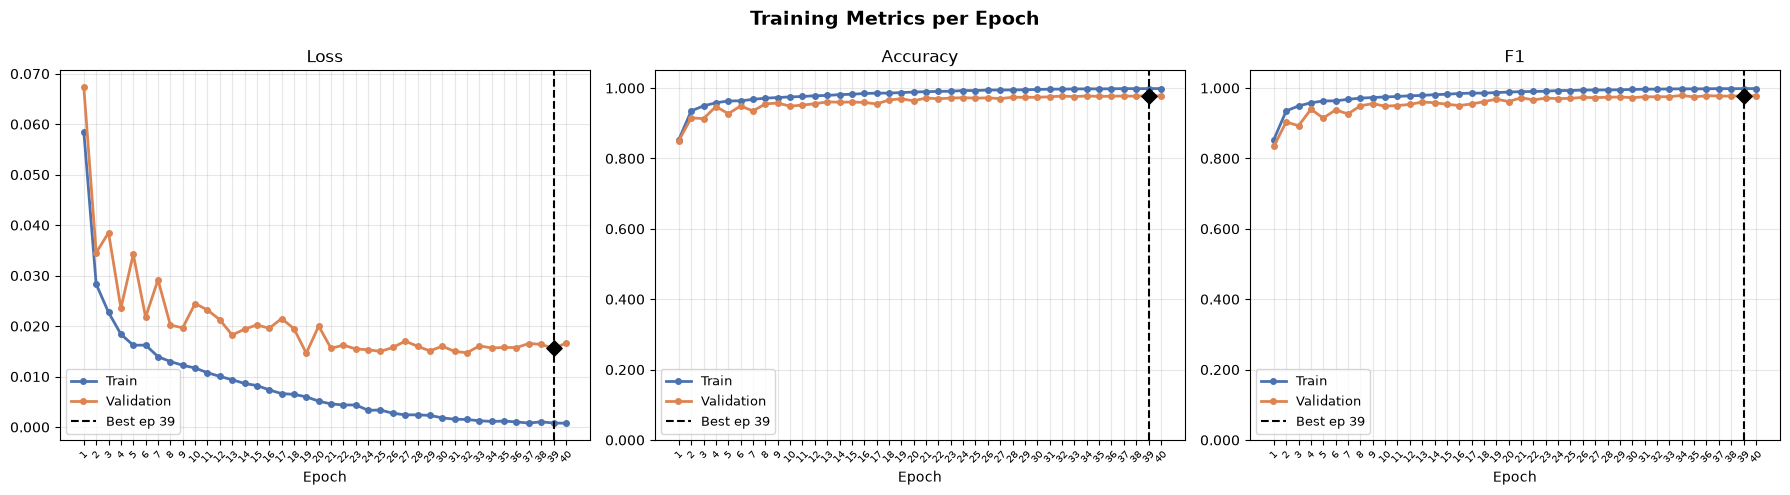

In [9]:
vis_train_baseline = Visualize(baseline_dir)
vis_train_baseline.plot_train()

========== baseline / messy ==========
  [Visualize] training_info.json not found in '/home/tjhinale/repo/Zooplankton_Classification/training_result/mnr/swin_t_cnn_baseline_08-25_messy_eval' — plot_train unavailable
Saved → /home/tjhinale/repo/Zooplankton_Classification/training_result/mnr/swin_t_cnn_baseline_08-25_messy_eval/confusion_matrix_level1.png


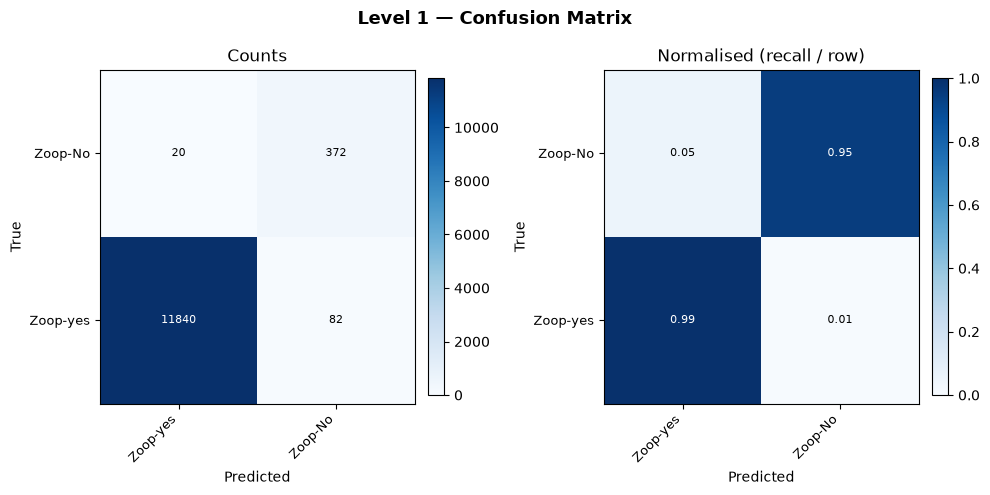

Saved → /home/tjhinale/repo/Zooplankton_Classification/training_result/mnr/swin_t_cnn_baseline_08-25_messy_eval/class_metrics_level1.png


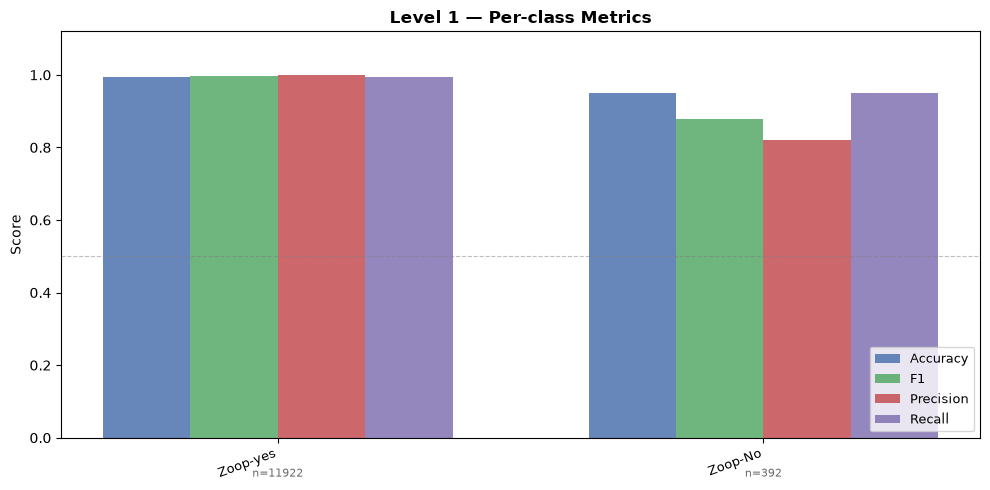

Saved → /home/tjhinale/repo/Zooplankton_Classification/training_result/mnr/swin_t_cnn_baseline_08-25_messy_eval/confusion_matrix_level2.png


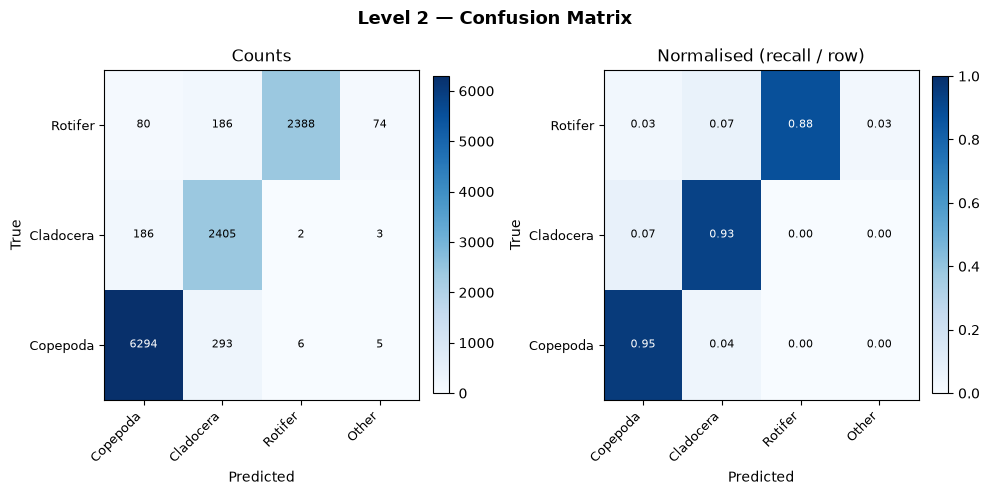

Saved → /home/tjhinale/repo/Zooplankton_Classification/training_result/mnr/swin_t_cnn_baseline_08-25_messy_eval/class_metrics_level2.png


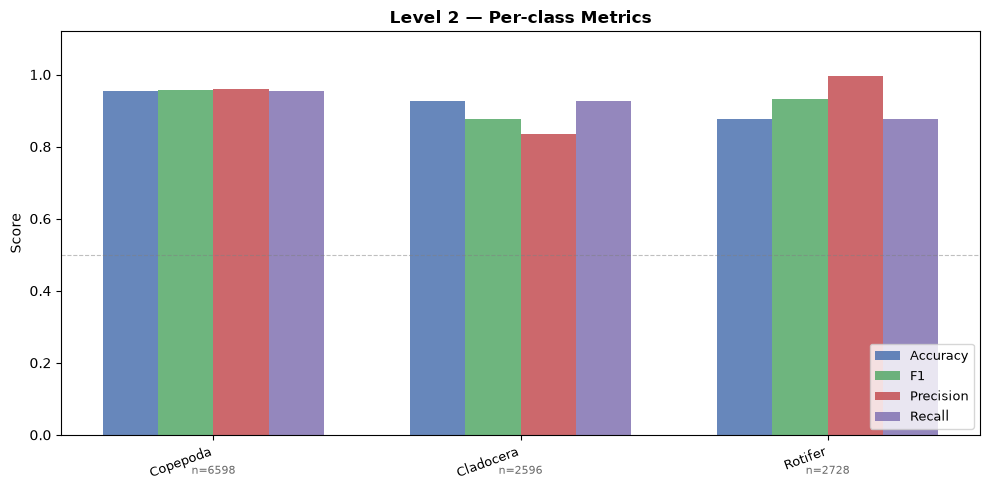

Saved → /home/tjhinale/repo/Zooplankton_Classification/training_result/mnr/swin_t_cnn_baseline_08-25_messy_eval/confusion_matrix_level3.png


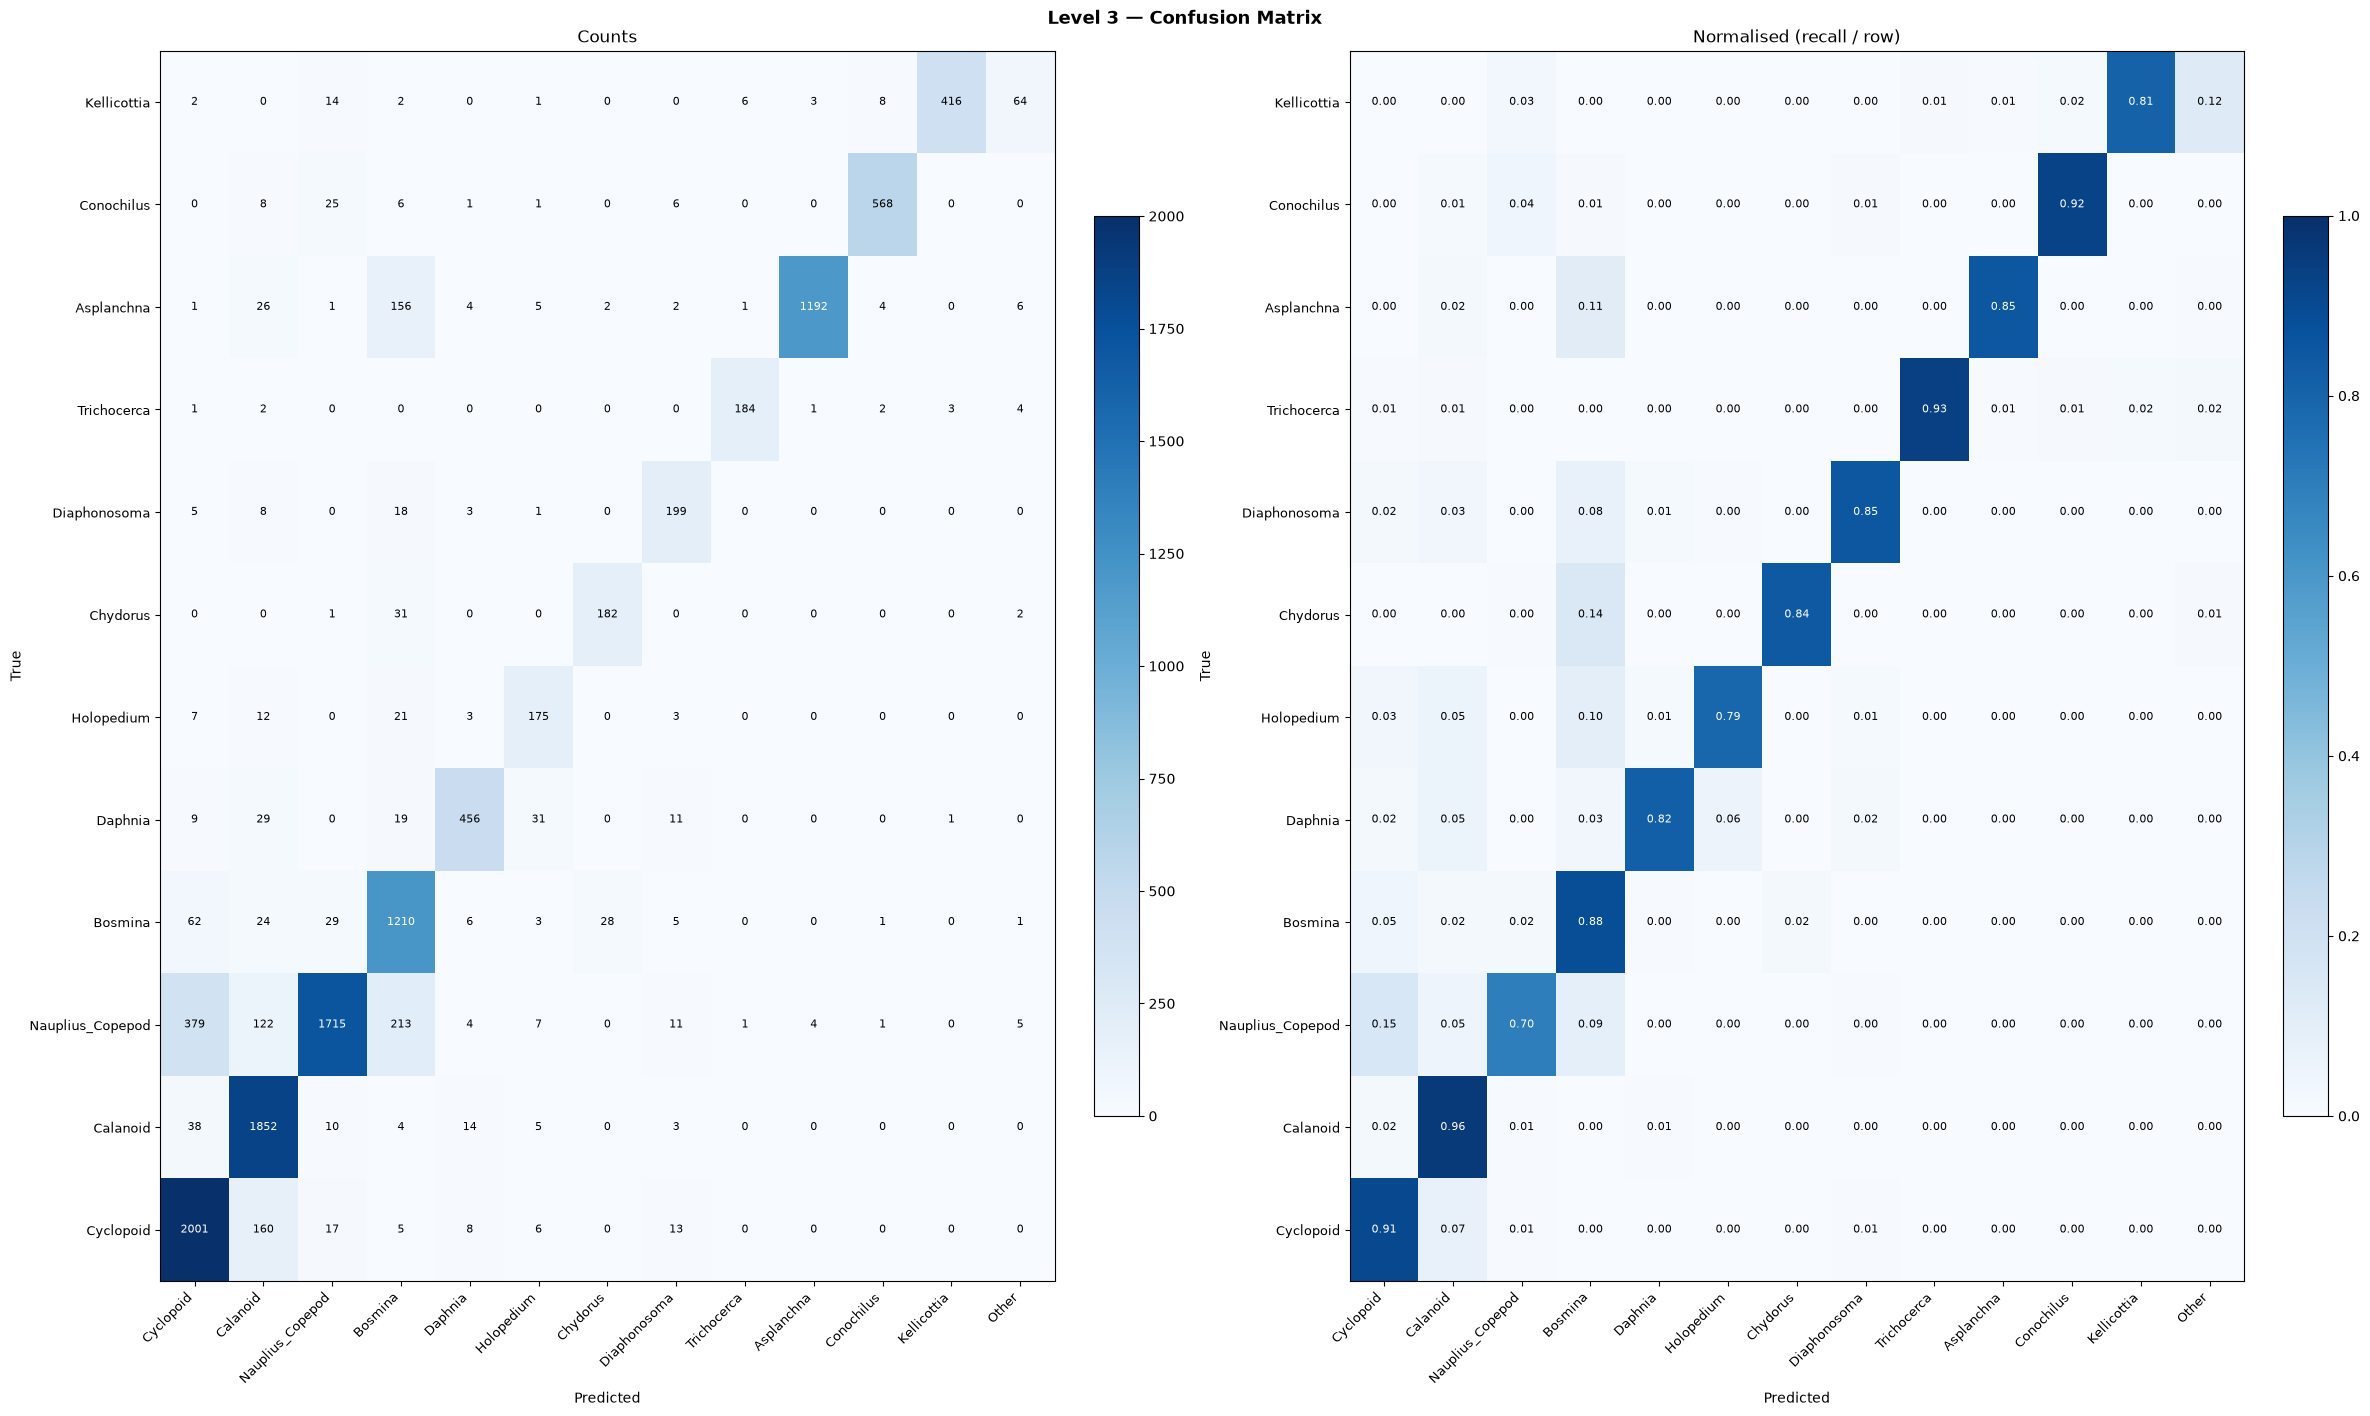

Saved → /home/tjhinale/repo/Zooplankton_Classification/training_result/mnr/swin_t_cnn_baseline_08-25_messy_eval/class_metrics_level3.png


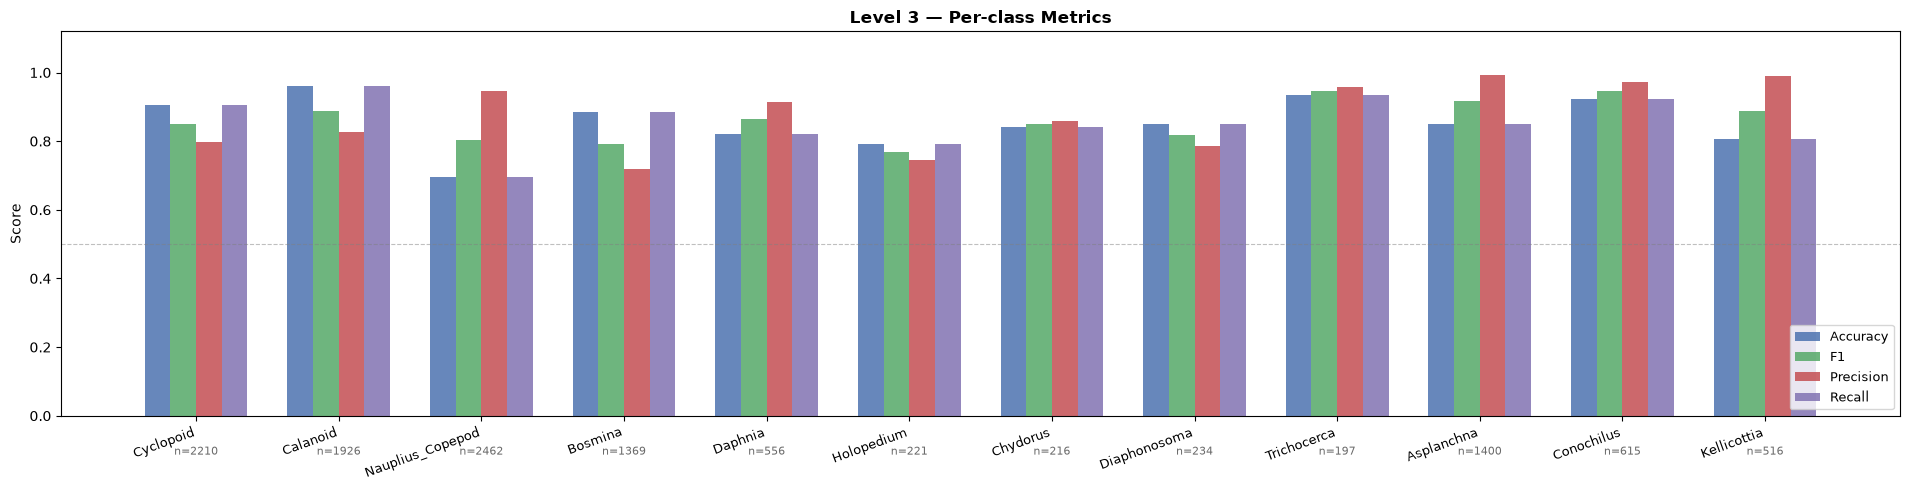

Saved → /home/tjhinale/repo/Zooplankton_Classification/training_result/mnr/swin_t_cnn_baseline_08-25_messy_eval/level_comparison.png


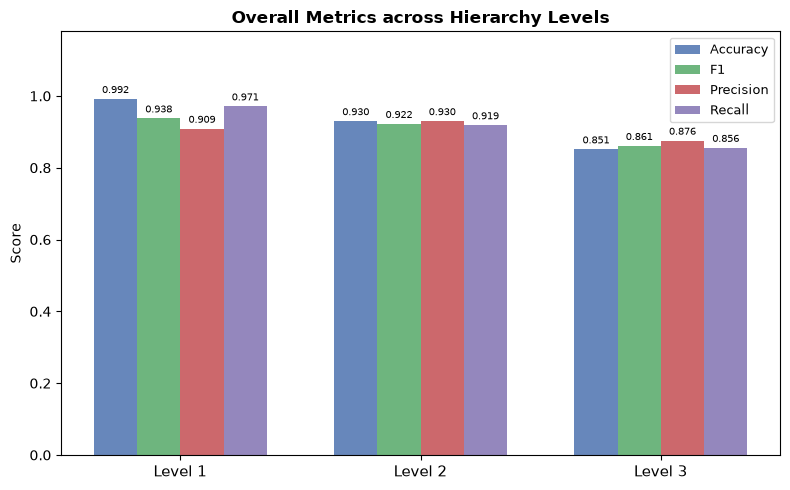

Saved → /home/tjhinale/repo/Zooplankton_Classification/training_result/mnr/swin_t_cnn_baseline_08-25_messy_eval/level_comparison.png


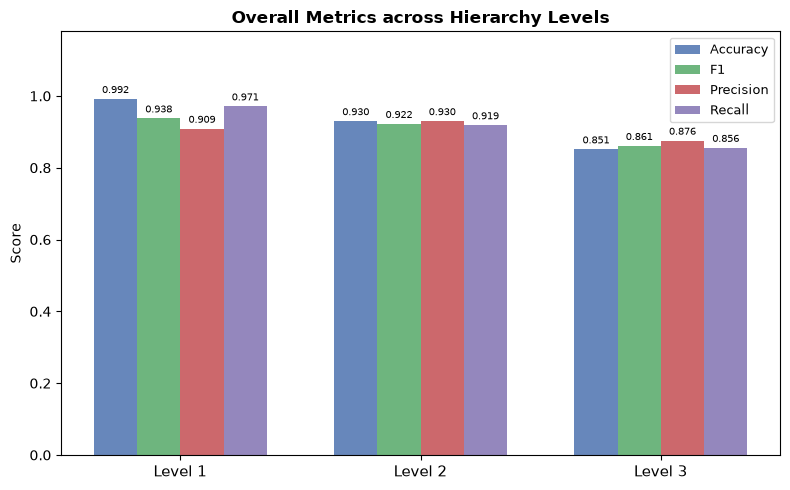

Saved → /home/tjhinale/repo/Zooplankton_Classification/training_result/mnr/swin_t_cnn_baseline_08-25_messy_eval/size_vs_accuracy.png


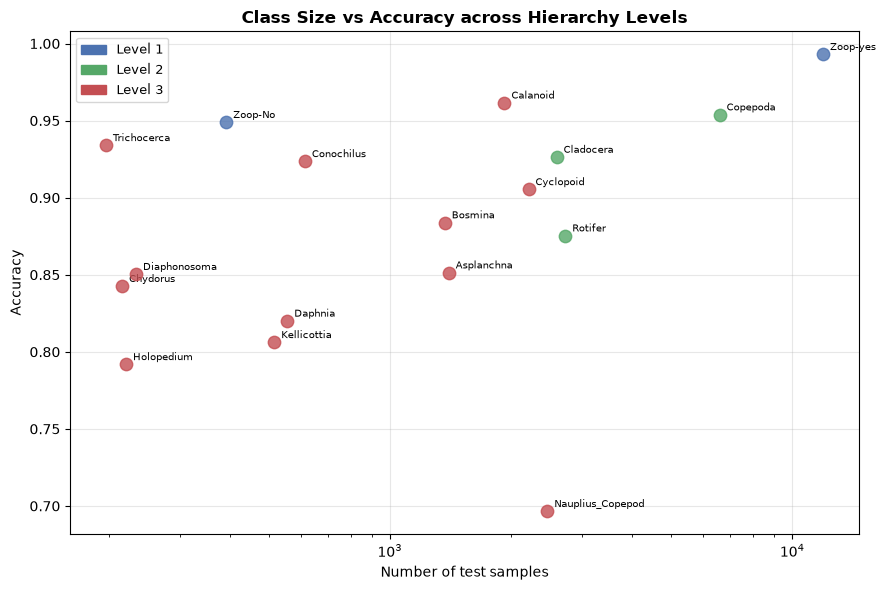

In [10]:
for tag in TARGETS:
    print(f'========== baseline / {tag} ==========')
    v = Visualize(f'{baseline_dir}_{tag}_eval')
    v.plot_pred()
    v.plot_level_comparison()
    v.plot_class_size_vs_accuracy()

# Visualize -- With background-noise augmentation

Saved → /home/tjhinale/repo/Zooplankton_Classification/training_result/mnr/swin_t_cnn_noise_08-25/train_metrics.png


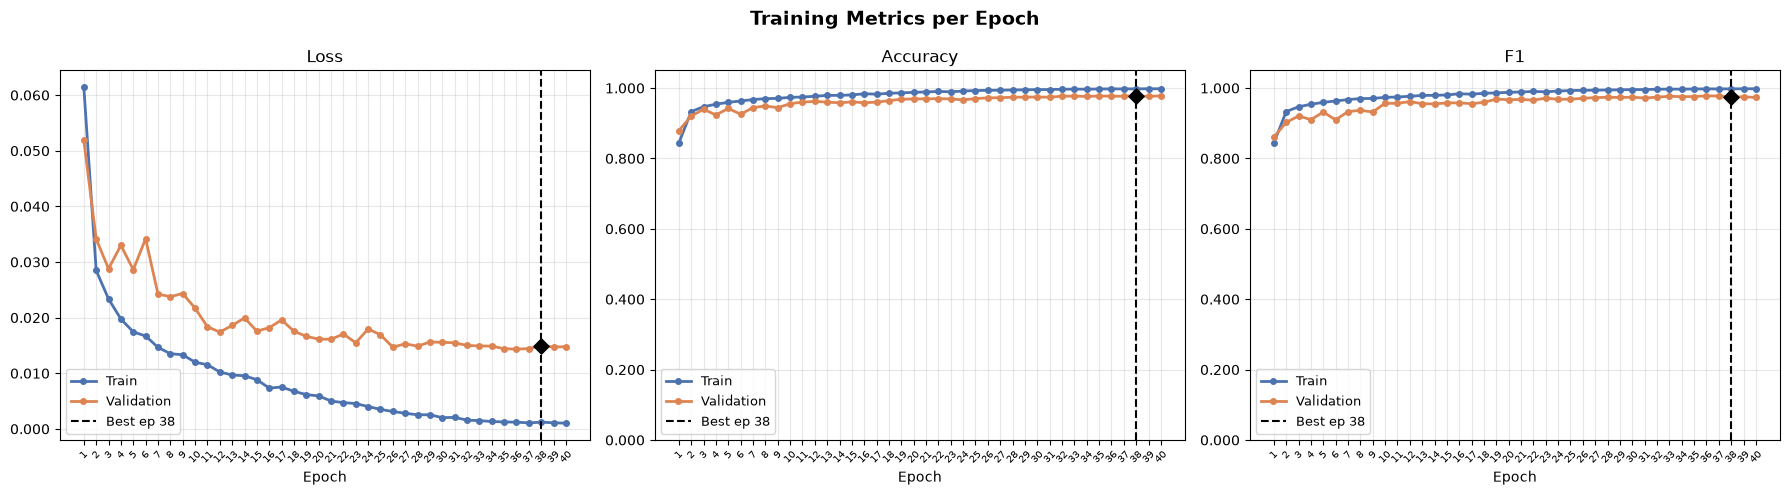

In [11]:
vis_train_noise = Visualize(noise_dir)
vis_train_noise.plot_train()

========== noise / messy ==========
  [Visualize] training_info.json not found in '/home/tjhinale/repo/Zooplankton_Classification/training_result/mnr/swin_t_cnn_noise_08-25_messy_eval' — plot_train unavailable
Saved → /home/tjhinale/repo/Zooplankton_Classification/training_result/mnr/swin_t_cnn_noise_08-25_messy_eval/level_comparison.png


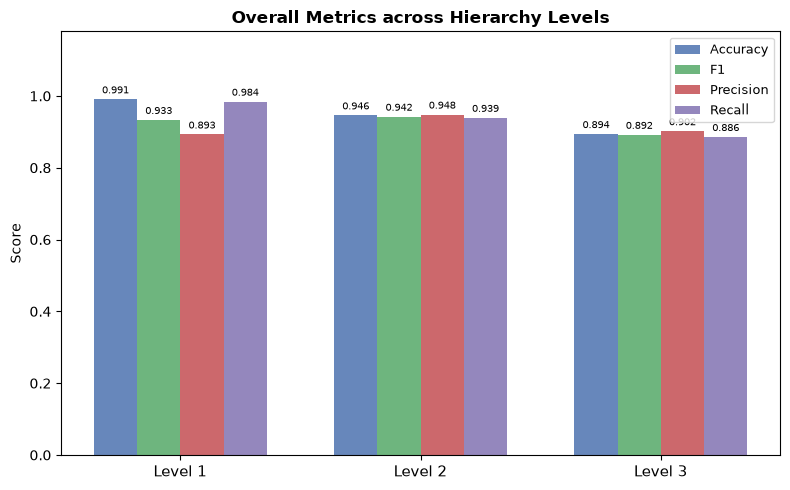

Saved → /home/tjhinale/repo/Zooplankton_Classification/training_result/mnr/swin_t_cnn_noise_08-25_messy_eval/size_vs_accuracy.png


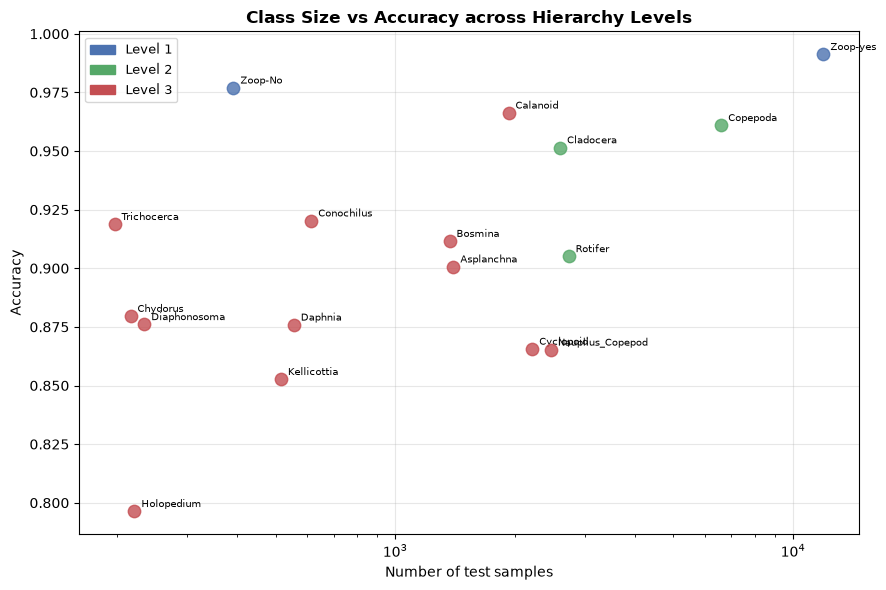

In [12]:
for tag in TARGETS:
    print(f'========== noise / {tag} ==========')
    v = Visualize(f'{noise_dir}_{tag}_eval')
    # v.plot_pred()
    v.plot_level_comparison()
    v.plot_class_size_vs_accuracy()

# Baseline vs. Noise: side-by-side comparison

Per-level overall metrics, baseline vs. noise-augmented training, shown once per target.

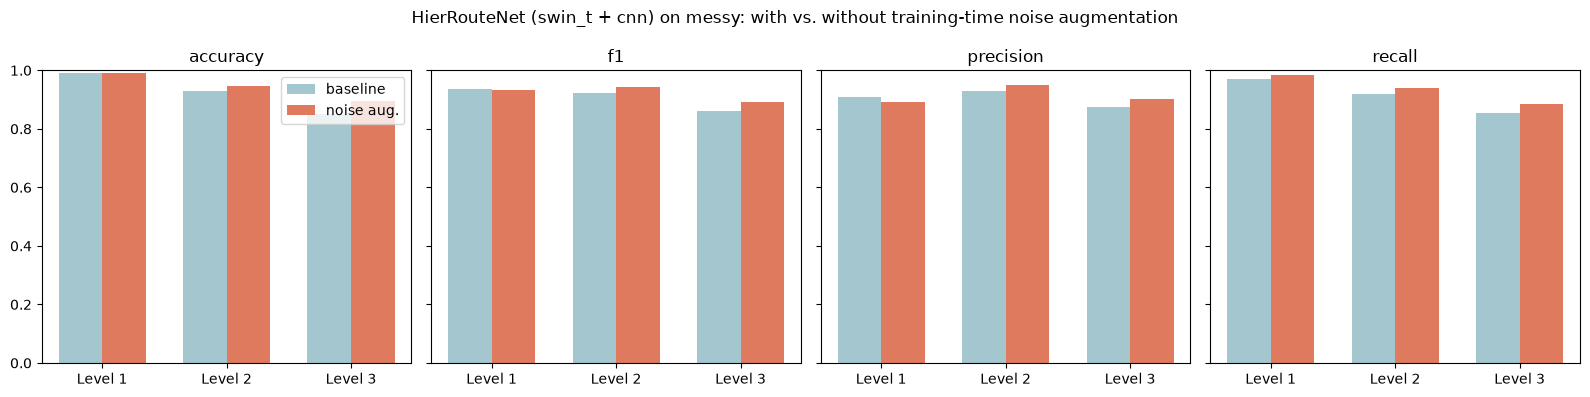


[messy]  Level  Metric      baseline    noise       delta     
        1      accuracy    0.9917      0.9908      -0.0009
        1      f1          0.9376      0.9333      -0.0043
        1      precision   0.9088      0.8928      -0.0160
        1      recall      0.9711      0.9842      +0.0131
        2      accuracy    0.9300      0.9461      +0.0161
        2      f1          0.9222      0.9424      +0.0202
        2      precision   0.9300      0.9482      +0.0182
        2      recall      0.9186      0.9392      +0.0206
        3      accuracy    0.8514      0.8940      +0.0426
        3      f1          0.8609      0.8919      +0.0310
        3      precision   0.8756      0.9019      +0.0263
        3      recall      0.8556      0.8858      +0.0302


In [13]:
metrics_to_plot = ['accuracy', 'f1', 'precision', 'recall']

for tag in TARGETS:
    rb, rn = level_results['baseline', tag], level_results['noise', tag]
    levels = sorted(rb)
    x = np.arange(len(levels))
    width = 0.35

    fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
    for ax, metric in zip(axes, metrics_to_plot):
        ax.bar(x - width / 2, [rb[l]['overall'][metric] for l in levels], width, label='baseline', color='#a3c6cf')
        ax.bar(x + width / 2, [rn[l]['overall'][metric] for l in levels], width, label='noise aug.', color='#e07a5f')
        ax.set_xticks(x)
        ax.set_xticklabels([f'Level {l}' for l in levels])
        ax.set_title(metric)
        ax.set_ylim(0, 1)
    axes[0].legend()
    fig.suptitle(f'HierRouteNet (swin_t + cnn) on {tag}: with vs. without training-time noise augmentation')
    plt.tight_layout()
    plt.show()

    print(f"\n[{tag}]  {'Level':<7}{'Metric':<12}{'baseline':<12}{'noise':<12}{'delta':<10}")
    for l in levels:
        for metric in metrics_to_plot:
            v1, v2 = rb[l]['overall'][metric], rn[l]['overall'][metric]
            print(f"        {l:<7}{metric:<12}{v1:<12.4f}{v2:<12.4f}{v2 - v1:+.4f}")

## Confidence

Per-class outcome breakdown under a confidence-threshold cascade: starting from the deepest level `HierRouteNet`'s greedy routing reached, accept that level's prediction if its local softmax confidence clears `CONFIDENCE_THRESHOLDS[level]`, else back off one level toward root. Logic lives in `runs/scripts/hiernet_eval.py` (`per_class_outcomes`, shared with `runs/confidence_threshold_experiment.ipynb` and `runs/experiment_scripts/confidence_threshold_table.py`). Run for every `(checkpoint, target)`.

Outcomes per sample, grouped by its *true* class:
- `correct` -- predicted the true leaf itself.
- `loosely correct` -- backed off to a genuine ancestor of the true leaf (right branch, coarser).
- `loosely incorrect` -- backed off, but to a node that isn't an ancestor either.
- `incorrect` -- committed to the deepest decision (no backoff) and got it wrong.
- `abstained` -- even the level-1 decision failed its threshold.

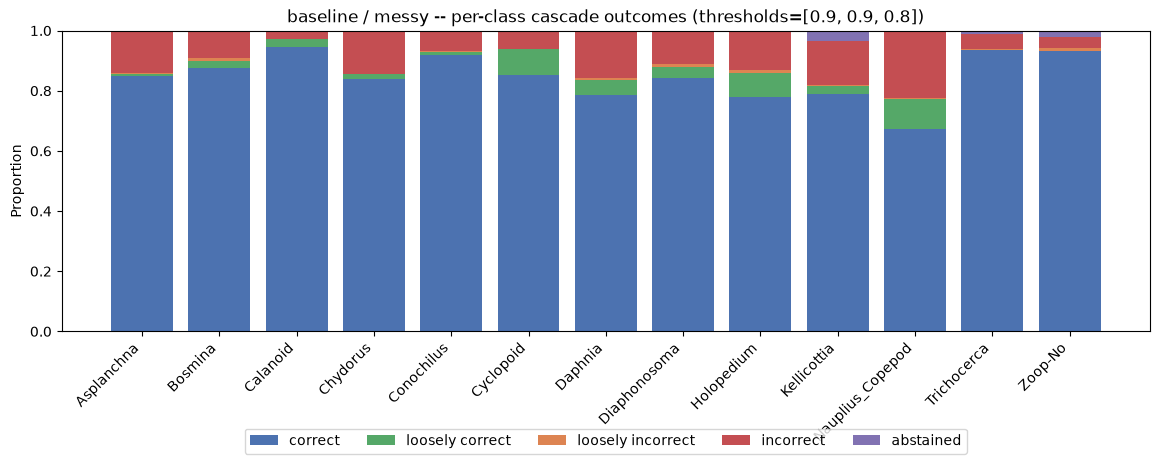

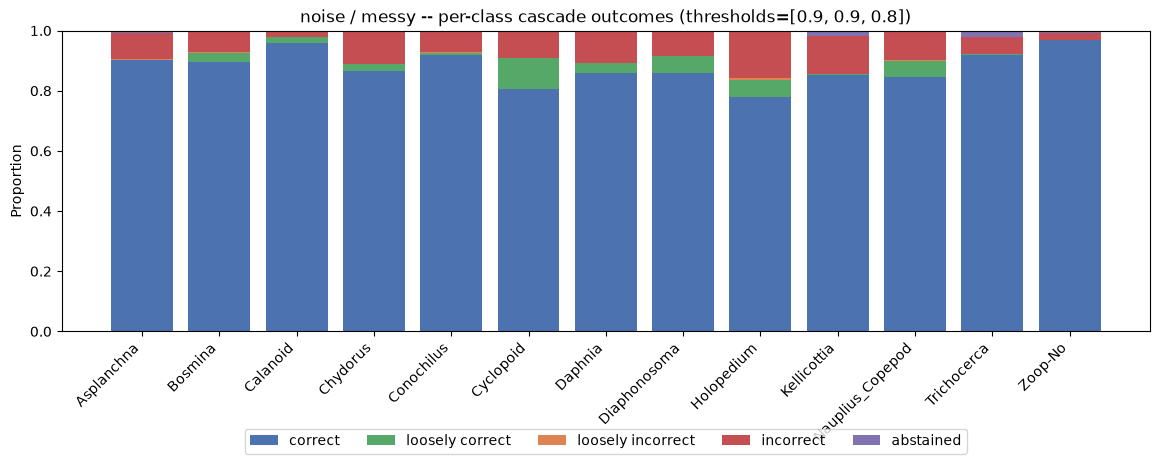

In [14]:
CONFIDENCE_THRESHOLDS = [0.9, 0.9, 0.8]

class_outcomes = {}
for ckpt_name in CHECKPOINTS:
    for tag, (ds, loader) in TARGETS.items():
        id_to_name = {v: k for k, v in ds.label_to_ids.items()}
        props = per_class_outcomes(
            models[ckpt_name, tag], loader, CONFIDENCE_THRESHOLDS,
            ds.hierarchy, id_to_name, device,
        )
        class_outcomes[ckpt_name, tag] = props
        plot_outcome_stacked_bar(
            props,
            f'{ckpt_name} / {tag} -- per-class cascade outcomes (thresholds={CONFIDENCE_THRESHOLDS})',
        )
        plt.show()

# Attention & Grad-CAM (noise-augmented model)

Run on a `Messy_background` sample. HIERNET's taxonomy has mixed leaf depth (`Bubbles`/`Exoskeleton`/`Fiber`/`Plant_Matter` are 2-edge leaves directly under `Zoop-No`, while e.g. `Cyclopoid` is a 3-edge leaf) -- the sample below is deliberately picked as a depth-3 leaf so the fixed 3-entry `weights` lists (matching `mnr.ipynb`'s full-path / species-level / top-level comparison) are valid for it.

Saved → /home/tjhinale/repo/Zooplankton_Classification/training_result/mnr/swin_t_cnn_noise_08-25_messy_eval/attention_map.png


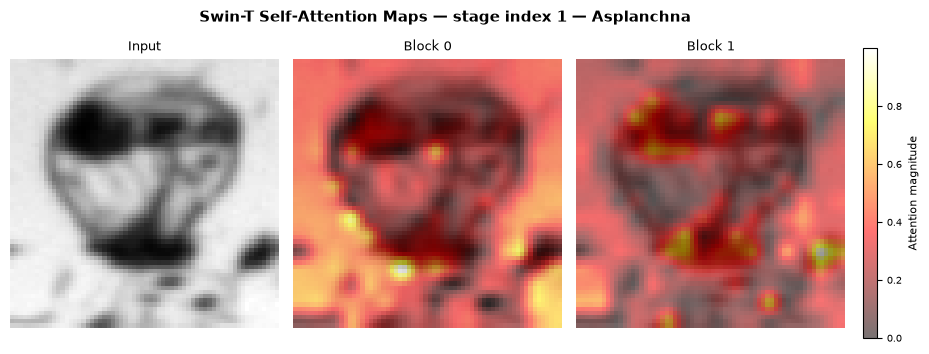

In [15]:
from PIL import Image

sample_idx = next(
    i for i, lbl in enumerate(messy_hier_dataset.labels)
    if messy_hier_dataset.hierarchy.nodes[lbl].depth == 3
)
sample_path = messy_hier_dataset.image_paths[sample_idx]
label_id = messy_hier_dataset.labels[sample_idx]
label_name = {v: k for k, v in messy_hier_dataset.label_to_ids.items()}[label_id]

img = Image.open(sample_path).convert('L')
img_tensor = transforms.Compose([
    transforms.Resize((RESOLUTION, RESOLUTION)),
    transforms.ToTensor(),
])(img).unsqueeze(0).repeat(1, 3, 1, 1)

fig = visualize_swin_attention(noise_model, img_tensor, stage=1,
                                label=label_name,
                                show_input=True,
                                overlay=True,
                                save_path=f'{noise_dir}_messy_eval/attention_map.png')

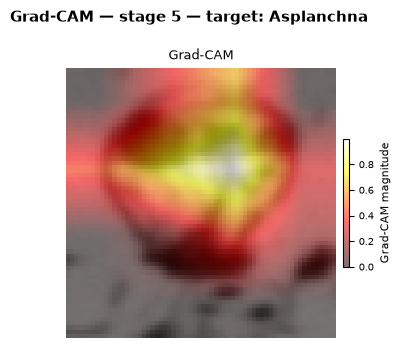

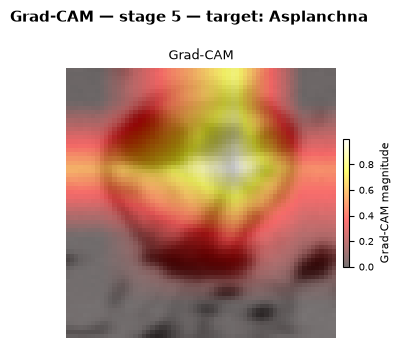

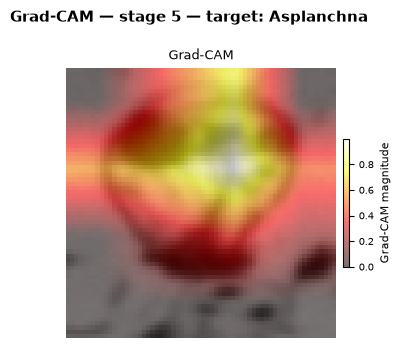

In [16]:
stage = 5
# Full hierarchical path
fig = visualize_gradcam(noise_model, img_tensor, label_name, weights=[1, 0, 0], stage=stage, overlay=True, show_input=False)

# Species level only (leaf decision only)
fig = visualize_gradcam(noise_model, img_tensor, label_name, weights=[1, 1, 0], stage=stage, overlay=True, show_input=False)

# Top-level only (zooplankton vs non-zooplankton)
fig = visualize_gradcam(noise_model, img_tensor, label_name, weights=[1, 1, 1], stage=stage, overlay=True, show_input=False)